In [2]:
import matplotlib.pyplot as plt
import networkx as nx

# Etapa 1 

## 1. Tabela de pesos do RA
- O RA dos caras é: **510187**
    - D1 = 5 
    - D2 = 1
    - D3 = 0
    - D4 = 1 
    - D5 = 8 
    - D6 = 7
- Se D6 é impar, então tlgd né: S6 é destino, S0 é ponto inicial 

In [3]:
e1 = 10 + (7 % 5)
e2 = 15 + (8 % 7)
e3 = 8 + (1 % 4)
e4 = 12 + (0 % 6)
e5 = 14 + (1 % 5)
e6 = 9 + (5 % 6)
e7 = 7 + ((8 + 7) % 5)
e8 = 11 + ((1 + 8) % 6)
e9 = 6 + ((0 + 1) % 4)
e10 = 16 + ((1 + 0) % 7)
e11 = 18 + ((5 + 1) % 8)
e12 = 9 + ((8 + 5) % 5)
e13 = 20 + (7 % 4)

print (e1)
print (e2)
print (e3)
print (e4)
print (e5)
print (e6)
print (e7)
print (e8)
print (e9)
print (e10)
print (e11)
print (e12)
print (e13)

12
16
9
12
15
14
7
14
7
17
24
12
23


## Criando o grafo

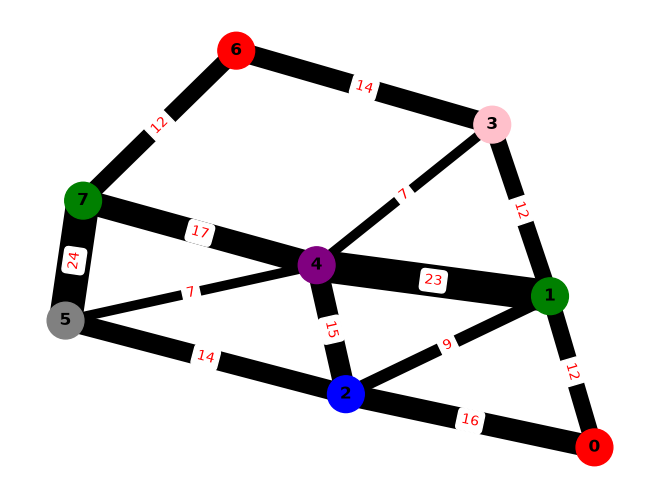

In [4]:
G = nx.Graph()

G.add_nodes_from([(0, {"color": "red"}),
                 (1, {"color": "green"}), 
                 (2, {"color": "blue"}),
                 (3, {"color": "pink"}),
                 (4, {"color": "purple"}), 
                 (5, {"color": "gray"}),
                 (6, {"color": "red"}),
                 (7, {"color": "green"}), 
                 ])

G.add_edge(0, 1, weight=e1)
G.add_edge(0, 2, weight=e2)
G.add_edge(1, 2, weight=e3)
G.add_edge(1, 3, weight=e4)
G.add_edge(2, 4, weight=e5)
G.add_edge(2, 5, weight=e6)
G.add_edge(3, 4, weight=e7)
G.add_edge(3, 6, weight=e8)
G.add_edge(4, 5, weight=e9)
G.add_edge(4, 7, weight=e10)
G.add_edge(5, 7, weight=e11)
G.add_edge(6, 7, weight=e12)
G.add_edge(1, 4, weight=e13)

# 2. Defina as posições dos nós (importante para alinhar texto e linhas)
pos = nx.spring_layout(G)

# 3. Extraia as cores dos nós e as propriedades das arestas
cores_dos_nos = [G.nodes[nó].get('color', 'lightblue') for nó in G.nodes()]

# Extrai os pesos para mostrar no gráfico
pesos_arestas = nx.get_edge_attributes(G, 'weight')

# Opcional: Extrai uma lista com as larguras das arestas baseada no peso
larguras = [G[u][v]['weight'] for u, v in G.edges()]

# 4. Desenhe o grafo básico (nós e linhas)
nx.draw(
    G, 
    pos, 
    with_labels=True, 
    node_color=cores_dos_nos, 
    width=larguras,          # Engrossa a linha baseado no peso
    node_size=700, 
    font_weight='bold'
)

# 5. Desenhe os rótulos dos pesos por cima das arestas
nx.draw_networkx_edge_labels(G, pos, edge_labels=pesos_arestas, font_color='red')

# 6. Exiba o grafo
plt.show()


## Matriz de adjacencia

In [5]:
matriz = nx.to_numpy_array(G, weight='weight').astype(object)

for i in range(len(matriz)): 
    for j in range(len(matriz[i])): 
        if matriz[i][j] == 0:
            matriz[i][j] = "NULO"

print(matriz)

[['NULO' 12.0 16.0 'NULO' 'NULO' 'NULO' 'NULO' 'NULO']
 [12.0 'NULO' 9.0 12.0 23.0 'NULO' 'NULO' 'NULO']
 [16.0 9.0 'NULO' 'NULO' 15.0 14.0 'NULO' 'NULO']
 ['NULO' 12.0 'NULO' 'NULO' 7.0 'NULO' 14.0 'NULO']
 ['NULO' 23.0 15.0 7.0 'NULO' 7.0 'NULO' 17.0]
 ['NULO' 'NULO' 14.0 'NULO' 7.0 'NULO' 'NULO' 24.0]
 ['NULO' 'NULO' 'NULO' 14.0 'NULO' 'NULO' 'NULO' 12.0]
 ['NULO' 'NULO' 'NULO' 'NULO' 17.0 24.0 12.0 'NULO']]


In [6]:
caminho = nx.dijkstra_path(G, source=0, target=6, weight='weight')

# Encontra o custo total (soma dos pesos) desse caminho
custo_total = nx.dijkstra_path_length(G, source=0, target=6, weight='weight')

print(f"Melhor caminho de 0 a 7: {caminho}")
print(f"Custo total do caminho: {custo_total}")


Melhor caminho de 0 a 7: [0, 1, 3, 6]
Custo total do caminho: 38


In [9]:
import math

NULO = None
INFINITO = math.inf

# TAD Grafo
class TipoGrafo:
    def __init__(self, n_max):
        self.numVertices = 0
        self.vertices = [None] * n_max
        self.matrizPesos = [[NULO] * n_max for _ in range(n_max)]

def ObterIndiceVertice(G, rot):
    for i in range(G.numVertices):
        if G.vertices[i] == rot:
            return i
    return -1

def InserirVertice(G, rot):
    G.vertices[G.numVertices] = rot
    G.numVertices += 1

def InserirAresta(G, rotA, rotB, peso):
    a, b = ObterIndiceVertice(G, rotA), ObterIndiceVertice(G, rotB)
    G.matrizPesos[a][b] = peso
    G.matrizPesos[b][a] = peso          # não direcionado: M[i][j] = M[j][i]

# Dijkstra
def Dijkstra(G, rotOrigem):
    n = G.numVertices
    dist = [INFINITO] * n
    ant = [-1] * n
    fechado = [False] * n
    dist[ObterIndiceVertice(G, rotOrigem)] = 0

    for _ in range(n):
        # 1. escolhe o aberto de menor dist (empate -> menor índice)
        u = -1
        for v in range(n):
            if not fechado[v] and dist[v] != INFINITO and (u == -1 or dist[v] < dist[u]):
                u = v
        if u == -1:
            break

        # 2. fecha u
        fechado[u] = True

        # 3. relaxa os vizinhos abertos
        for v in range(n):
            peso = G.matrizPesos[u][v]
            if peso is not NULO and not fechado[v] and dist[u] + peso < dist[v]:
                dist[v] = dist[u] + peso
                ant[v] = u

    return dist, ant

def Rota(G, ant, rotDestino):
    rota = []
    v = ObterIndiceVertice(G, rotDestino)
    while v != -1:
        rota.insert(0, G.vertices[v])
        v = ant[v]
    return rota

# grafo do meu RA
G = TipoGrafo(8)
for i in range(8):
    InserirVertice(G, f"S{i}")
ramais = [("S0", "S1", 12), ("S0", "S2", 16), ("S1", "S2", 9), ("S1", "S3", 12), ("S2", "S4", 15),
          ("S2", "S5", 14), ("S3", "S4", 7), ("S3", "S6", 14), ("S4", "S5", 7), ("S4", "S7", 17),
          ("S5", "S7", 24), ("S6", "S7", 12), ("S1", "S4", 23)]
for a, b, p in ramais:
    InserirAresta(G, a, b, p)

dist, ant = Dijkstra(G, "S0")
print(Rota(G, ant, "S6"))


['S0', 'S1', 'S3', 'S6']


## Ponte caindo e tals

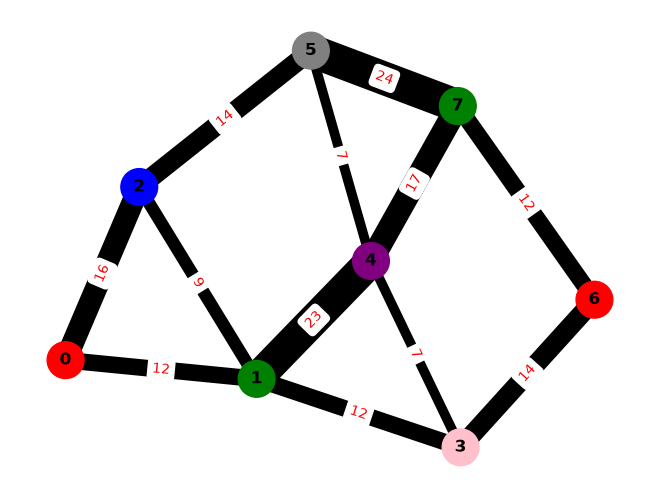

In [10]:
G_nova = nx.Graph()

G_nova.add_nodes_from([(0, {"color": "red"}),
                 (1, {"color": "green"}), 
                 (2, {"color": "blue"}),
                 (3, {"color": "pink"}),
                 (4, {"color": "purple"}), 
                 (5, {"color": "gray"}),
                 (6, {"color": "red"}),
                 (7, {"color": "green"}), 
                 ])

G_nova.add_edge(0, 1, weight=e1)
G_nova.add_edge(0, 2, weight=e2)
G_nova.add_edge(1, 2, weight=e3)
G_nova.add_edge(1, 3, weight=e4)
G_nova.add_edge(2, 5, weight=e6)
G_nova.add_edge(3, 4, weight=e7)
G_nova.add_edge(3, 6, weight=e8)
G_nova.add_edge(4, 5, weight=e9)
G_nova.add_edge(4, 7, weight=e10)
G_nova.add_edge(5, 7, weight=e11)
G_nova.add_edge(6, 7, weight=e12)
G_nova.add_edge(1, 4, weight=e13)

# 2. Defina as posições dos nós (importante para alinhar texto e linhas)
pos = nx.spring_layout(G_nova)

# 3. Extraia as cores dos nós e as propriedades das arestas
cores_dos_nos = [G_nova.nodes[nó].get('color', 'lightblue') for nó in G_nova.nodes()]

# Extrai os pesos para mostrar no gráfico
pesos_arestas = nx.get_edge_attributes(G_nova, 'weight')

# Opcional: Extrai uma lista com as larguras das arestas baseada no peso
larguras = [G_nova[u][v]['weight'] for u, v in G_nova.edges()]

# 4. Desenhe o grafo básico (nós e linhas)
nx.draw(
    G_nova, 
    pos, 
    with_labels=True, 
    node_color=cores_dos_nos, 
    width=larguras,          # Engrossa a linha baseado no peso
    node_size=700, 
    font_weight='bold'
)

# 5. Desenhe os rótulos dos pesos por cima das arestas
nx.draw_networkx_edge_labels(G_nova, pos, edge_labels=pesos_arestas, font_color='red')

# 6. Exiba o grafo
plt.show()


In [11]:
caminho_novo = nx.dijkstra_path(G_nova, source=0, target=6, weight='weight')

# Encontra o custo total (soma dos pesos) desse caminho
custo_total = nx.dijkstra_path_length(G_nova, source=0, target=6, weight='weight')

print(f"Melhor caminho de S0 a S6: {caminho_novo}")
print(f"Melhor caminho de S0 a S6: {caminho}")
print(f"Custo total do caminho: {custo_total}")


Melhor caminho de S0 a S6: [0, 1, 3, 6]
Melhor caminho de S0 a S6: [0, 1, 3, 6]
Custo total do caminho: 38


In [14]:
G_nova = TipoGrafo(8)
for i in range(8):
    InserirVertice(G_nova, f"S{i}")
for a, b, p in ramais:
    if (a, b) != ("S2", "S4"):          # e5 caiu
        InserirAresta(G_nova, a, b, p)

dist, ant = Dijkstra(G_nova, "S0")
print(Rota(G_nova, ant, "S6"))
print(Rota(G_nova, ant, "S4"))
print(Rota(G, ant, "S4"))




['S0', 'S1', 'S3', 'S6']
['S0', 'S1', 'S3', 'S4']
['S0', 'S1', 'S3', 'S4']


In [15]:
G_nx = nx.Graph()
for a, b, p in ramais:
    G_nx.add_edge(a, b, weight=p)

mst_prim = nx.minimum_spanning_tree(G_nx, weight='weight', algorithm='prim')

print("Arestas selecionadas pelo Prim:")
custo_total_mst = 0
for u, v, data in mst_prim.edges(data=True):
    peso = data['weight']
    custo_total_mst += peso
    print(f"Aresta ({u} - {v}) com peso: {peso}")
print(f"Custo total da MST: {custo_total_mst} km")


Arestas selecionadas pelo Prim:
Aresta (S0 - S1) com peso: 12
Aresta (S1 - S3) com peso: 12
Aresta (S1 - S2) com peso: 9
Aresta (S3 - S4) com peso: 7
Aresta (S3 - S6) com peso: 14
Aresta (S4 - S5) com peso: 7
Aresta (S6 - S7) com peso: 12
Custo total da MST: 73 km


In [ ]:
# Prim
def Prim(G, rotInicio, pai):
    n = G.numVertices
    chave = [INFINITO] * n
    naArvore = [False] * n
    for v in range(n):
        pai[v] = -1
    chave[ObterIndiceVertice(G, rotInicio)] = 0
    custoTotal = 0

    for _ in range(n):
        # 1. escolhe o vértice fora da árvore com menor chave (empate -> menor índice)
        u = -1
        for v in range(n):
            if not naArvore[v] and chave[v] != INFINITO and (u == -1 or chave[v] < chave[u]):
                u = v
        if u == -1:
            break                              # grafo desconexo

        # 2. coloca u na árvore
        naArvore[u] = True
        custoTotal += chave[u]                 # peso da aresta (pai[u], u)

        # 3. atualiza os vizinhos fora da árvore
        for v in range(n):
            peso = G.matrizPesos[u][v]
            # DIFERENÇA PARA O DIJKSTRA: compara só o peso da aresta, sem somar a distância acumulada
            if peso is not NULO and not naArvore[v] and peso < chave[v]:
                chave[v] = peso
                pai[v] = u

    return custoTotal

# grafo completo do meu RA (nome próprio pra não brigar com o G do NetworkX)
G_prim = TipoGrafo(8)
for i in range(8):
    InserirVertice(G_prim, f"S{i}")
for a, b, p in ramais:
    InserirAresta(G_prim, a, b, p)

pai = [None] * 8
custo_mst = Prim(G_prim, "S0", pai)

for v in range(8):
    if pai[v] != -1:
        print(f"({G_prim.vertices[pai[v]]}, {G_prim.vertices[v]}) = {G_prim.matrizPesos[pai[v]][v]} km")
print(custo_mst)

(S0, S1) = 12 km
(S1, S2) = 9 km
(S1, S3) = 12 km
(S3, S4) = 7 km
(S4, S5) = 7 km
(S3, S6) = 14 km
(S6, S7) = 12 km
73
